# D3 – Data Analysis: Return Rates by Product Category
**Course:** IT135IU – Introduction to Data Science  
**Group members:**    
                    Dang Uyen Thu - ITDSIU25044 - Product Owner  
                    Truong Thuan Tuan- ITDSIU25051 - Data Engineer  
                    Nguyen An Khoi - ITDSIU25016 - Data Analyst  
                    Nguyen Thi Khanh Linh - ITDSIU25019 - Visualisation lead  
                    Nguyen Chi Phuc - ITDSIU25028 - Reproducibility lead  
                    Dang Le Truc Linh - ITDSIU25018 - Ethics and privacy officer  
**Objective:** Analyze the working dataset to determine which product categories generate the most returns and whether it is worth acting on.

---

In [1]:
import pandas as pd
import numpy as np
import re
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

# Fixed random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Loading data from raw CSVs...")
# Note for Reproducibility: The CSV files are stored in data/raw/ (see README)
df1 = pd.read_csv("../data/raw/retail1.csv", dtype={"InvoiceNo": str, "StockCode": str})
df2 = pd.read_csv("../data/raw/retail2.csv", dtype={"Invoice": str, "StockCode": str})

# Align schema and merge
df2 = df2.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID"})
common_cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
df = pd.concat([df1, df2[common_cols]], ignore_index=True)

# Deduplicate overlapping transactions (same logic as D2)
df = df.drop_duplicates(subset=common_cols, keep="first")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Define cancellations (Invoice starting with 'C')
df["is_cancellation"] = df["InvoiceNo"].astype(str).str.startswith("C")

# Apply the exact same keyword rules as D2 to categorize products
CATEGORY_KEYWORDS = {
    "Kitchen & Dining": ("MUG", "MUGS", "CUP", "CUPS", "TEACUP", "TEA CUPS", "TEAPOT", "TEA POT", "SAUCER", "PLATE", "PLATES", "BOWL", "BOWLS", "CUTLERY", "SPOON", "FORK", "KNIFE", "KETTLE", "JUG", "DISH", "DISHES", "KITCHEN", "PANTRY", "APRON", "OVEN", "CAKE", "BAKING", "MOULD", "MOULDS", "COOKING", "CHOPPING", "TRAY", "JAR", "JARS", "COASTER", "COASTERS", "GLASS BOWL", "BREAKFAST SET", "POPCORN"),
    "Home Decor": ("CANDLE", "CANDLES", "T-LIGHT", "TEALIGHT", "HOME DECOR", "VASE", "VASES", "FRAME", "FRAMES", "DOORMAT", "WREATH", "ORNAMENT", "MIRROR", "CLOCK", "COAT RACK", "CUSHION", "CUSHIONS", "GARLAND", "CABINET", "CHEST", "CHALKBOARD", "WALL SIGN", "TRINKET", "HEART", "WICKER"),
    "Toys & Games": ("TOY", "TOYS", "GAME", "GAMES", "PUZZLE", "PUZZLES", "PLAYING CARDS", "DOLL", "DOLLY", "TEDDY", "SKIPPING ROPE", "KITE", "MARBLES", "JIGSAW", "BUILDING BLOCK", "YO-YO"),
    "Stationery & Gifts": ("CARD", "CARDS", "NOTEBOOK", "NOTEBOOKS", "PEN", "PENCIL", "STENCIL", "CRAFT", "STICKER", "GIFT WRAP", "WRAP", "TAG", "TISSUE", "RIBBON", "ENVELOPE", "PAPER", "POSTAGE"),
    "Bags & Accessories": ("BAG", "BAGS", "PURSE", "WALLET", "POUCH", "PARASOL", "UMBRELLA", "KEYRING", "KEY RING", "LUGGAGE", "SUITCASE"),
    "Clothing & Accessories": ("SCARF", "HAT", "GLOVE", "SOCK", "SHIRT", "T-SHIRT", "DRESS", "SKIRT", "JACKET", "COAT", "BOOT", "SHOE", "SLIPPER", "MITTEN", "HEADBAND", "HAIRBAND", "BRACELET", "NECKLACE", "EARRING", "JEWEL", "TIE"),
    "Garden & Outdoor": ("GARDEN", "PLANTER", "WATERING", "FLOWER", "PLANT", "KNEELING", "BIRD BATH", "WHEELBARROW", "SEED", "OUTDOOR"),
    "Lighting": ("FAIRY LIGHT", "LIGHT", "LIGHTS", "LAMP", "LAMPS", "BULB", "BULBS")
}

description = df["Description"].fillna("").astype(str).str.upper()
df["Category"] = pd.NA
for category, keywords in CATEGORY_KEYWORDS.items():
    pattern = r"\b(?:" + "|".join(re.escape(k) for k in keywords) + r")\b"
    matches = description.str.contains(pattern, regex=True, na=False)
    assign = df["Category"].isna() & matches
    df.loc[assign, "Category"] = category
df["Category"] = df["Category"].fillna("Other / Unclassified")

print(f"Total rows after merge: {len(df):,}")

Loading data from raw CSVs...


Total rows after merge: 1,033,036


## 1. Data Cleaning & Outlier Handling

To ensure the analysis reflects genuine customer behavior, we apply the following cleaning steps:
1. **Filter Non-Products:** We keep only rows where `StockCode` matches a 5-digit pattern, removing postage, discounts, and manual adjustments.
2. **Remove Extreme Outliers:** We remove transactions with an absolute Quantity >= 10,000. Of the 15 removed lines, 4 are two sale/cancellation pairs (80,995 and 74,215 units) and 11 are very large positive orders (10,000–19,152 units, mostly priced at £0–£0.25). Keeping these would artificially inflate the return value (numerator) and distort the gross sales (denominator) of their categories.
3. **Define Sales and Returns:** We define sales as positive quantities with valid prices, and returns as cancelled invoices with negative quantities.

In [2]:
# 1. Filter non-product rows
df_prod = df[df["StockCode"].str.match(r"^\d{5}", na=False)].copy()
print(f"Removed {len(df) - len(df_prod):,} non-product rows.")

# 2. Remove extreme outliers
before_outliers = len(df_prod)
df_prod = df_prod[df_prod["Quantity"].abs() < 10000].copy()
print(f"Removed {before_outliers - len(df_prod):,} lines with extreme Quantity (|Quantity| >= 10,000).")

# 3. Define Sales (valid purchases) and Returns (cancellations)
sales = df_prod[(~df_prod["is_cancellation"]) & (df_prod["Quantity"] > 0) & (df_prod["UnitPrice"] > 0)].copy()
rets = df_prod[(df_prod["is_cancellation"]) & (df_prod["Quantity"] < 0) & (df_prod["UnitPrice"] > 0)].copy()

# 4. Log dropped negative quantities with evidence
dropped_neg = df_prod[(~df_prod["is_cancellation"]) & (df_prod["Quantity"] < 0)]
print(f"Dropped {len(dropped_neg):,} negative-quantity rows without 'C' prefix (likely inventory adjustments).")
print(f"  -> Evidence: {dropped_neg['CustomerID'].isna().mean():.0%} have no CustomerID; "
      f"Top UnitPrice values are: {dropped_neg['UnitPrice'].unique()[:3]}")

print(f"\nFinal Sales lines: {len(sales):,}")
print(f"Final Return lines: {len(rets):,}")

Removed 5,980 non-product rows.
Removed 15 lines with extreme Quantity (|Quantity| >= 10,000).
Dropped 3,362 negative-quantity rows without 'C' prefix (likely inventory adjustments).
  -> Evidence: 100% have no CustomerID; Top UnitPrice values are: [0.]

Final Sales lines: 1,003,203
Final Return lines: 17,912


In [3]:
# Sensitivity of the outlier threshold (top 3 categories by return-value rate)
base = df[df["StockCode"].str.match(r"^\d{5}", na=False)]
for t in [1000, 5000, 10000, 100000]:
    d = base[base["Quantity"].abs() < t]
    r = d[(d.is_cancellation) & (d.Quantity < 0) & (d.UnitPrice > 0)]
    s = d[(~d.is_cancellation) & (d.Quantity > 0) & (d.UnitPrice > 0)]
    rv = -(r.Quantity * r.UnitPrice).groupby(r.Category).sum()
    gs = (s.Quantity * s.UnitPrice).groupby(s.Category).sum()
    print(f"|Quantity| < {t:>6}:", (rv / gs).sort_values(ascending=False).head(3).round(4).to_dict())

|Quantity| <   1000: {'Lighting': 0.0617, 'Kitchen & Dining': 0.0288, 'Clothing & Accessories': 0.023}
|Quantity| <   5000: {'Lighting': 0.0603, 'Kitchen & Dining': 0.0331, 'Home Decor': 0.0247}


|Quantity| <  10000: {'Lighting': 0.0603, 'Kitchen & Dining': 0.0335, 'Home Decor': 0.0247}
|Quantity| < 100000: {'Stationery & Gifts': 0.1403, 'Lighting': 0.0603, 'Kitchen & Dining': 0.0566}


## 2. Descriptive Statistics & Return Metrics

To answer "is it worth acting on", we calculate two metrics per category:
1. **Return Rate by Line (Frequency):** How often items are returned based on line count.
2. **Return Rate by Value (Financial Impact):** The percentage of gross revenue lost to returns. We prioritize this metric for the business recommendation because a single high-value return hurts more than several low-value ones.
3. **Excess Return Value:** The absolute financial loss (£) exceeding the system-wide average return rate.

In [4]:
# Calculate revenue per line
sales["line_total"] = sales["Quantity"] * sales["UnitPrice"]
rets["line_total"] = rets["Quantity"] * rets["UnitPrice"]

# Aggregate by Category
cat = pd.DataFrame({
    "sales_lines":    sales.groupby("Category").size(),
    "return_lines":   rets.groupby("Category").size(),
    "gross_sales":    sales.groupby("Category")["line_total"].sum(),
    "returned_value": -rets.groupby("Category")["line_total"].sum(),
}).fillna(0)

cat["net_revenue"]       = cat["gross_sales"] - cat["returned_value"]
cat["return_rate_lines"] = cat["return_lines"] / (cat["sales_lines"] + cat["return_lines"])
cat["return_rate_value"] = cat["returned_value"] / cat["gross_sales"]
cat["revenue_share"]     = cat["gross_sales"] / cat["gross_sales"].sum()

# Calculate Excess Return Value
overall_rate = cat.returned_value.sum() / cat.gross_sales.sum()
cat["excess_return_value"] = cat.returned_value - overall_rate * cat.gross_sales

print(f"'Other / Unclassified' share of sales: {cat.loc['Other / Unclassified', 'sales_lines'] / cat['sales_lines'].sum():.1%}")
print(f"Overall system return rate (by value): {overall_rate:.2%}\n")

# Display top categories by Value Return Rate
display_cols = ["sales_lines", "return_lines", "gross_sales", "returned_value", "return_rate_value", "excess_return_value"]
print(cat.sort_values("return_rate_value", ascending=False)[display_cols].round(3))

'Other / Unclassified' share of sales: 38.3%
Overall system return rate (by value): 2.43%

                        sales_lines  return_lines  gross_sales  \
Category                                                         
Lighting                      15930           817    488014.19   
Kitchen & Dining             167643          4689   3135150.98   
Home Decor                   184006          3708   4152199.10   
Clothing & Accessories        10191           111    132604.64   
Other / Unclassified         383770          5710   7169360.91   
Stationery & Gifts            88656           749   1213213.00   
Toys & Games                  33844           377    570802.57   
Garden & Outdoor              25792           411    408334.35   
Bags & Accessories            93371          1340   2110329.61   

                        returned_value  return_rate_value  excess_return_value  
Category                                                                        
Lighting            

## 3. Statistical Relationship

We use the **Chi-square test of independence** to examine if there is a statistically significant relationship between the product `Category` and the likelihood of an item being returned. We also report **Cramér's V** to measure the effect size (since p-values become negligible with large datasets). Finally, we calculate 95% Wilson Confidence Intervals for the line return rates.

In [5]:
# Chi-square test
tab = cat[["sales_lines", "return_lines"]].astype(int)
chi2, p, dof, expected = stats.chi2_contingency(tab)

n = tab.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))

p_str = "< 0.001" if p < 0.001 else f"{p:.3g}"
print(f"Chi-square: {chi2:.1f}, p-value: {p_str}")
print(f"Cramér's V: {cramers_v:.4f} (small effect)")

# Wilson Confidence Intervals
rows = []
for c, r in cat.iterrows():
    N = int(r.sales_lines + r.return_lines)
    p_hat = r.return_lines / N
    lo, hi = proportion_confint(r.return_lines, N, alpha=0.05, method="wilson")
    rows.append((c, p_hat, lo, hi))

ci = pd.DataFrame(rows, columns=["Category", "rate", "ci_low", "ci_high"]).sort_values("rate", ascending=False)
print("\n--- 95% Confidence Interval of Return Rate (Line-based) ---")
print(ci.round(4))

Chi-square: 2740.1, p-value: < 0.001
Cramér's V: 0.0518 (small effect)

--- 95% Confidence Interval of Return Rate (Line-based) ---
                 Category    rate  ci_low  ci_high
5                Lighting  0.0488  0.0456   0.0522
4        Kitchen & Dining  0.0272  0.0265   0.0280
3              Home Decor  0.0198  0.0191   0.0204
2        Garden & Outdoor  0.0157  0.0143   0.0173
6    Other / Unclassified  0.0147  0.0143   0.0150
0      Bags & Accessories  0.0141  0.0134   0.0149
8            Toys & Games  0.0110  0.0100   0.0122
1  Clothing & Accessories  0.0108  0.0090   0.0130
7      Stationery & Gifts  0.0084  0.0078   0.0090


## 4. Interpretation and Limitations

### Interpretation of Findings
The analysis reveals a statistically significant relationship between product category and return behavior (Chi-square p-value < 0.001). However, the effect size is small (Cramér's V = 0.0518), indicating that category alone explains only a fraction of why items are returned.

A sensitivity check shows that the top two categories by return-value rate (Lighting and Kitchen & Dining) are unchanged for outlier thresholds between 1,000 and 10,000; only third place varies at the strictest threshold. When the threshold is raised to 100,000, which keeps the extreme bulk orders (e.g., 80,995 and 74,215 units), Stationery & Gifts jumps to a 14.0% return-value rate and Kitchen & Dining to 5.7%. This confirms that these few extreme transactions, not typical customer behaviour, drive the distortion, and justifies removing them.

To answer "is it worth acting on", we use **Excess Return Value** (the financial loss exceeding the system-wide average return rate of 2.43%) rather than just return frequency:
- **Kitchen & Dining** is the highest financial priority. Despite a moderate return rate (3.35%), its large revenue base means it generates the highest excess loss (~£28,933).
- **Lighting** has the highest return frequency (6.03%), but due to lower sales volume, its excess loss is only ~£17,582. It warrants a low-cost investigation (e.g., packaging checks) rather than a major overhaul.
- **Home Decor** has a return rate near the system average, yielding almost zero excess loss (~£1,538).

### What the analysis does NOT establish
1. **Metric Consistency:** Chi-square and Confidence Intervals are computed on *line rates* (frequency), while our financial ranking uses *value rate*. We chose value rate for ranking because it directly reflects financial loss.
2. **Cancellation as a Proxy:** The dataset lacks a literal "returned" field. We used `InvoiceNo` starting with 'C' as a proxy, which may include orders cancelled before shipping.
3. **Unlinked Records:** We cannot link a cancelled invoice to its original purchase, so the "return rate" is calculated per line item, not per order. The Wilson CIs assume independence, which is violated when multiple lines belong to the same invoice.
4. **Heuristic Categorization:** 38.3% of lines fell into "Other / Unclassified" due to our keyword rules.
5. **Revenue, Not Profit:** `line_total` is gross revenue, not profit. We lack cost data to calculate margin loss.
6. **Correlation is not Causation:** A higher return rate in a category does not show that its products are defective. The data cannot isolate the cause (e.g., shipping damage, buyer's remorse, seasonal gifting).
7. **Time Span:** All £ figures cover the whole dataset period (Dec 2009 – Dec 2011, about two years), not a single year.

In [6]:
import os

OUT_DIR = "../data/processed"
os.makedirs(OUT_DIR, exist_ok=True)

# Export data containing excess_return_value for Khanh Linh
cat.to_csv(f"{OUT_DIR}/category_summary.csv")
ci.to_csv(f"{OUT_DIR}/category_return_rate_ci.csv", index=False)

print("Successfully exported CSVs for the Visualisation Lead.")
print(f"Check files in: {OUT_DIR}/")

Successfully exported CSVs for the Visualisation Lead.
Check files in: ../data/processed/


### Appendix: rows removed as outliers

In [7]:
df_prod_all = df[df["StockCode"].str.match(r"^\d{5}", na=False)]
print("Rows with |Quantity| >= 10000:")
df_prod_all[df_prod_all.Quantity.abs() >= 10000][
    ["InvoiceNo","Description","Quantity","UnitPrice","Category"]]

Rows with |Quantity| >= 10000:


,InvoiceNo,Description,Quantity,UnitPrice,Category
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,Kitchen & Dining
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,Kitchen & Dining
502122,578841,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,Stationery & Gifts
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,Stationery & Gifts
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,Stationery & Gifts
632766,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,Kitchen & Dining
669075,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,Kitchen & Dining
669076,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,Kitchen & Dining
669077,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,Kitchen & Dining
669078,501534,SET/6 WOODLAND PAPER CUPS,12744,0.10,Kitchen & Dining


## 5. Visualisations
The following charts are generated by the Data Analyst and handed over to the Visualisation Lead. They use the `cat` and `ci` dataframes generated in the previous steps.

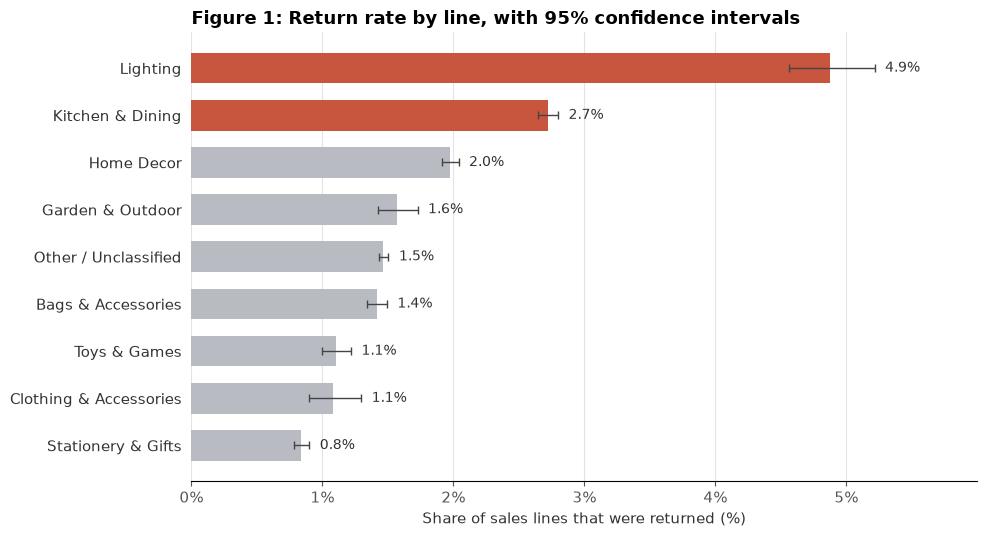

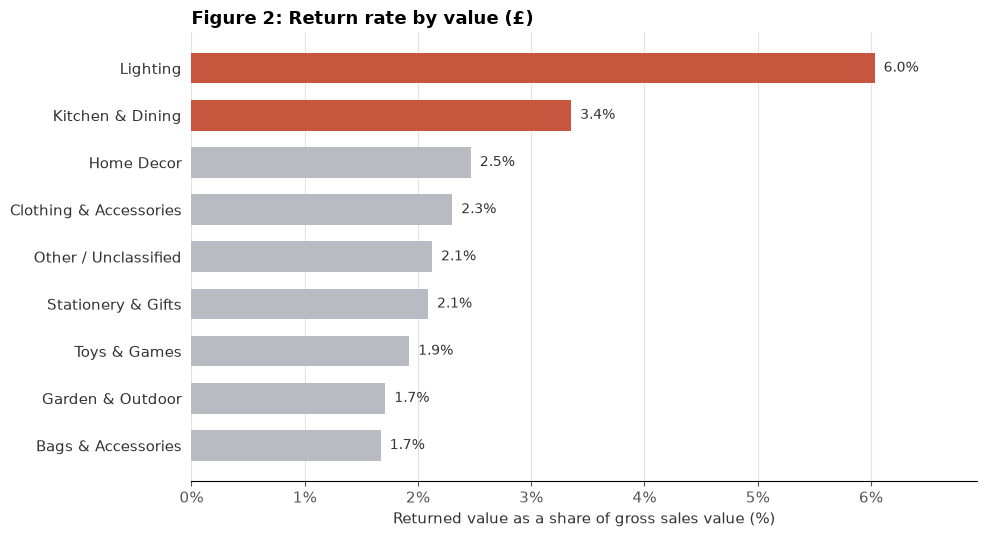

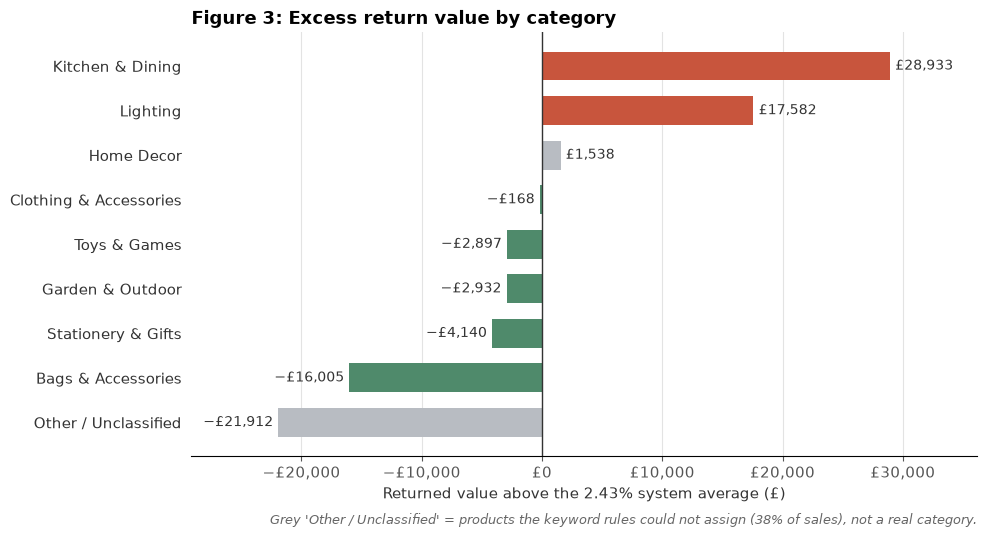

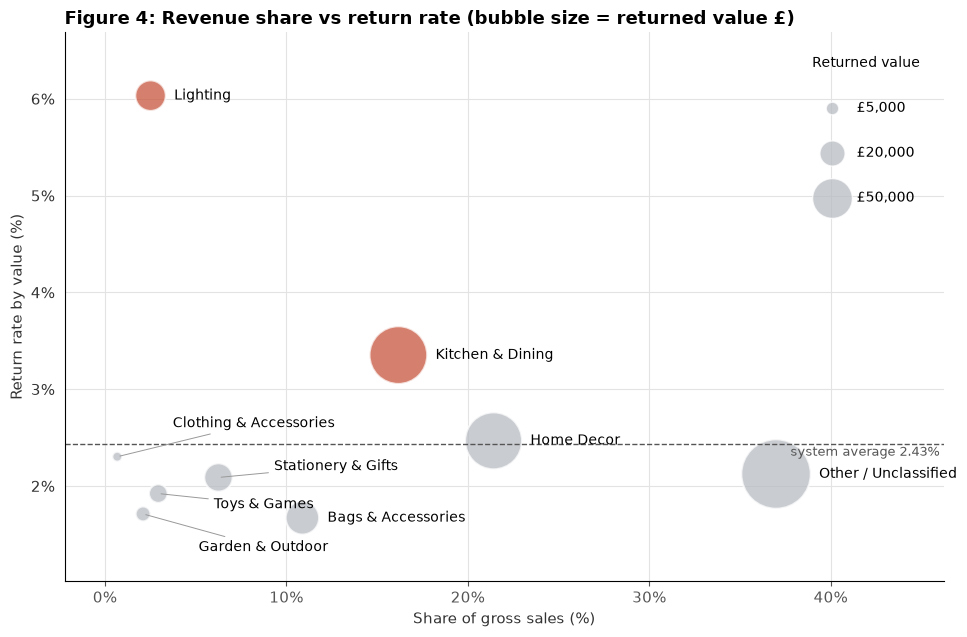

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import os

# Ensure the figures directory exists
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Shared style: no box, light grid, readable fonts
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": "#333333",
    "xtick.color": "#555555",
    "ytick.color": "#333333",
    "ytick.left": False,
})

TARGETS = ["Lighting", "Kitchen & Dining"]
color_highlight = "#c8553d"  # main targets (Lighting & Kitchen)
color_normal = "#b8bcc2"     # other categories
color_good = "#4f8a6b"       # better than the system average


def gbp(v):
    return f"£{v:,.0f}" if v >= 0 else f"−£{-v:,.0f}"


def finish(ax, fname):
    ax.grid(axis="x", color="#e3e3e3", linewidth=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{fname}", dpi=300, bbox_inches="tight")
    plt.show()


# ==========================================
# Figure 1: Return Rate by Line with 95% CI
# ==========================================
ci_sorted = ci.sort_values("rate", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
colors1 = [color_highlight if c in TARGETS else color_normal for c in ci_sorted["Category"]]
ax.barh(ci_sorted["Category"], ci_sorted["rate"], color=colors1, height=0.65,
        xerr=[ci_sorted["rate"] - ci_sorted["ci_low"], ci_sorted["ci_high"] - ci_sorted["rate"]],
        error_kw=dict(ecolor="#444444", capsize=3, elinewidth=1))
for y, (r, hi) in enumerate(zip(ci_sorted["rate"], ci_sorted["ci_high"])):
    ax.text(hi + 0.0008, y, f"{r:.1%}", va="center", fontsize=10, color="#333333")
ax.set_xlabel("Share of sales lines that were returned (%)")
ax.set_title("Figure 1: Return rate by line, with 95% confidence intervals")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, ci_sorted["ci_high"].max() * 1.15)
finish(ax, "chart1_return_rate_lines_ci.png")

# ==========================================
# Figure 2: Return Rate by Value (£)
# ==========================================
cat_sorted_val = cat.sort_values("return_rate_value", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
colors2 = [color_highlight if c in TARGETS else color_normal for c in cat_sorted_val.index]
ax.barh(cat_sorted_val.index, cat_sorted_val["return_rate_value"], color=colors2, height=0.65)
for y, v in enumerate(cat_sorted_val["return_rate_value"]):
    ax.text(v + 0.0008, y, f"{v:.1%}", va="center", fontsize=10, color="#333333")
ax.set_xlabel("Returned value as a share of gross sales value (%)")
ax.set_title("Figure 2: Return rate by value (£)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, cat_sorted_val["return_rate_value"].max() * 1.15)
finish(ax, "chart2_return_rate_value.png")

# ==========================================
# Figure 3: Excess Return Value (£)
# ==========================================
cat_sorted_ex = cat.sort_values("excess_return_value", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
# "Other / Unclassified" is not a real product group, so keep it neutral grey
colors3 = [color_highlight if c in TARGETS else
           (color_normal if c == "Other / Unclassified" or v >= 0 else color_good)
           for c, v in cat_sorted_ex["excess_return_value"].items()]
ax.barh(cat_sorted_ex.index, cat_sorted_ex["excess_return_value"], color=colors3, height=0.65)
span = cat_sorted_ex["excess_return_value"].abs().max()
for y, v in enumerate(cat_sorted_ex["excess_return_value"]):
    ax.text(v + (0.015 if v >= 0 else -0.015) * span, y, gbp(v), va="center",
            ha="left" if v >= 0 else "right", fontsize=10, color="#333333")
ax.axvline(0, color="#333333", linewidth=1)
ax.set_xlabel("Returned value above the 2.43% system average (£)")
ax.text(1.0, -0.16, "Grey 'Other / Unclassified' = products the keyword rules could not assign (38% of sales), not a real category.",
        transform=ax.transAxes, ha="right", fontsize=9, color="#666666", style="italic")
ax.set_title("Figure 3: Excess return value by category")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: gbp(x)))
ax.set_xlim(cat_sorted_ex["excess_return_value"].min() - 0.25 * span,
            cat_sorted_ex["excess_return_value"].max() + 0.25 * span)
finish(ax, "chart3_excess_return_value.png")

# ==========================================
# Figure 4: Revenue Share vs Return Rate (Bubble Chart)
# ==========================================
fig, ax = plt.subplots(figsize=(10, 6.5))
size_scale = 2500 / cat["returned_value"].max()
colors4 = [color_highlight if c in TARGETS else color_normal for c in cat.index]
ax.scatter(cat["revenue_share"], cat["return_rate_value"], s=cat["returned_value"] * size_scale,
           c=colors4, alpha=0.75, edgecolors="white", linewidth=1.5)

# Label each bubble; small categories crowd the bottom-left, so spread their labels out
sizes4 = cat["returned_value"] * size_scale
offsets = {c: (sizes4[c] ** 0.5 / 2 + 6, 0) for c in cat.index}  # just right of each bubble
crowded = cat[(cat["revenue_share"] < 0.08) & (cat["return_rate_value"] < 0.03)].sort_values("return_rate_value").index
for i, c in enumerate(crowded):
    offsets[c] = (40, -24 + 16 * i)
for c, row in cat.iterrows():
    dx, dy = offsets[c]
    ax.annotate(c, (row["revenue_share"], row["return_rate_value"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=10, va="center", ha="left",
                arrowprops=dict(arrowstyle="-", color="#999999", lw=0.7) if c in crowded else None)

# Size legend: what a bubble of a given £ returned value looks like
for v in [5_000, 20_000, 50_000]:
    ax.scatter([], [], s=v * size_scale, c=color_normal, alpha=0.75, edgecolors="white", label=f"£{v:,}")
ax.legend(title="Returned value", loc="upper right", frameon=False, labelspacing=2.2,
          borderpad=1.2, scatterpoints=1, title_fontsize=10, fontsize=10)

ax.axhline(0.0243, color="#555555", linestyle="--", linewidth=1)
ax.text(0.995, 0.0241, "system average 2.43%", transform=ax.get_yaxis_transform(), va="top", ha="right",
        fontsize=9, color="#555555")
ax.set_xlabel("Share of gross sales (%)")
ax.set_ylabel("Return rate by value (%)")
ax.set_title("Figure 4: Revenue share vs return rate (bubble size = returned value £)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(color="#e3e3e3", linewidth=0.8)
ax.spines["left"].set_visible(True)
ax.set_axisbelow(True)
ax.margins(x=0.08, y=0.15)
ax.set_xlim(right=cat["revenue_share"].max() * 1.25)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/chart4_revenue_vs_return.png", dpi=300, bbox_inches="tight")
plt.show()

### Chart Captions & Take-aways

**Figure 1: Return Rate by Line with 95% Confidence Intervals**
*Description:* This chart displays the frequency of returned items (line rate) for each product category, along with the 95% Wilson Confidence Intervals. The two most problematic categories are highlighted in red.
*Take-away:* **Lighting (~4.9%)** and **Kitchen & Dining (~2.7%)** have significantly higher return frequencies than other categories. The non-overlapping confidence intervals confirm that their high return rates are statistically significant, not due to random variation.

**Figure 2: Return Rate by Value (Financial Impact)**
*Description:* This chart measures the percentage of gross revenue lost to returns for each category. While Figure 1 measures frequency, this chart measures financial damage.
*Take-away:* When measured by value, **Lighting remains the highest (~6.0%)**, followed closely by **Kitchen & Dining (~3.4%)**. Home Decor sits right at the system average. *(Note: Confidence intervals are not displayed here due to the lack of independence between line items within the same invoice).*

**Figure 3: Excess Return Value (£)**
*Description:* This chart explicitly answers the question "Is it worth acting on?". It calculates the absolute financial loss (£) that exceeds the system-wide average return rate of 2.43%. Categories with green bars perform better than the company average (negative excess).
*Take-away:* **Kitchen & Dining generates the largest excess financial loss (+£28,933)**, followed by **Lighting (+£17,582)**. Although Lighting has a higher *percentage* return rate, Kitchen & Dining's massive sales volume means it bleeds more actual money.

**Figure 4: Revenue Share vs Return Rate (Bubble Chart)**
*Description:* This scatter plot maps each category based on its Revenue Share (X-axis) and Return Rate by Value (Y-axis). The size of the bubble represents the absolute returned value (£). The red bubbles represent our two main targets.
*Take-away:* **Lighting** has a high return rate but only accounts for a small fraction (~2.6%) of the total revenue. In contrast, **Kitchen & Dining** is located in the top-right quadrant, meaning it combines a high return rate with a massive revenue share. Therefore, addressing Kitchen & Dining will yield the highest Return on Investment (ROI) for the business.